In [1]:
import matplotlib.pyplot as plt
import numpy as np
import keras_ocr
from PIL import Image

In [2]:
from tensorflow.keras.layers import StringLookup
from tensorflow import keras

import tensorflow as tf
import os

np.random.seed(42)
tf.random.set_seed(42)

The image needs to be a jpeg file. This is more suitable for the application.

In [3]:
tf_img = tf.io.read_file("image_50402305.JPG")
tf_img = tf.image.decode_jpeg(tf_img, 1)
tf_img = tf.cast(tf_img, tf.float32) / 255.0

In [4]:
# Black and white the image

img = Image.open("image_50402305.JPG")
img = img.convert("1")
img.save("image_50402305_bw.JPG")

In [5]:
pipeline = keras_ocr.pipeline.Pipeline()

images = [keras_ocr.tools.read("image_50402305_bw.JPG"), keras_ocr.tools.read("image_50402305.JPG")]

prediction_groups = pipeline.recognize(images) # Note that an image from the directory can be passed here

Looking for C:\Users\sures\.keras-ocr\craft_mlt_25k.h5
Looking for C:\Users\sures\.keras-ocr\crnn_kurapan.h5
13/13 [==============================] - 36s 3s/step


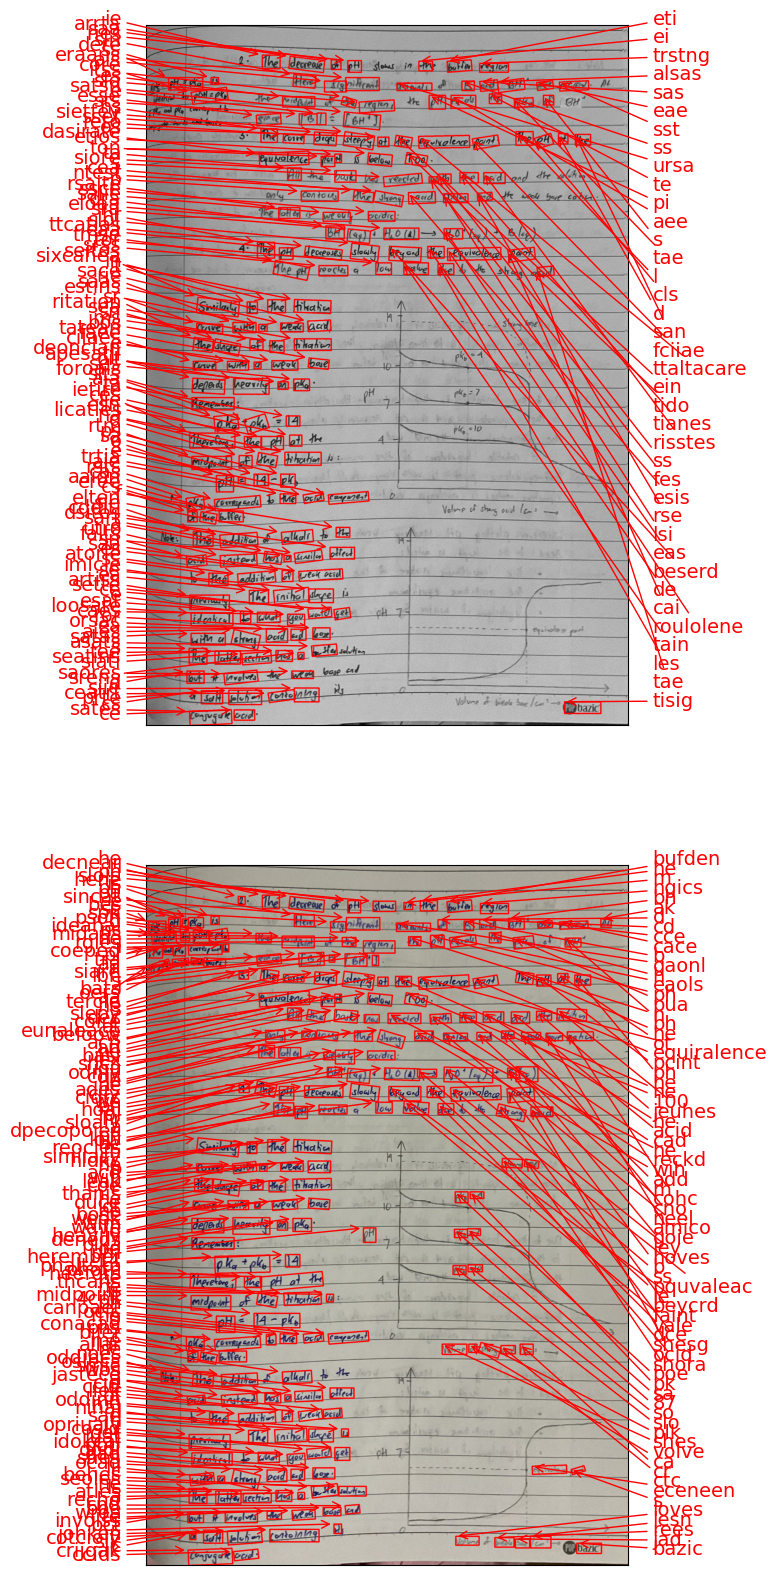

In [6]:
fig, axs = plt.subplots(nrows=len(images), figsize=(10, 20))
for ax, image, predictions in zip(axs, images, prediction_groups):
    keras_ocr.tools.drawAnnotations(image=image, 
                                    predictions=predictions, 
                                    ax=ax)

# Easyocr

In [ ]:
import easyocr

reader = easyocr.Reader(['en'], gpu=False)

In [ ]:
image = keras_ocr.tools.read("https://drive.google.com/uc?id=1aX43391FACX_8bo0nxPZrSx9iGQV0oPU")
results = reader.readtext(image)

In [ ]:
PlotRes = [ (word[1], np.array(word[0])) for word in results]

In [ ]:
fig, axs = plt.subplots(nrows=1, figsize=(20, 20))
keras_ocr.tools.drawAnnotations(image=image, predictions=PlotRes, ax=axs)
plt.show()

In [ ]:
prediction_groups.append(PlotRes)
images.append(image)

HandwrittenRecog

In [ ]:
def extract(data) :
    for word in data :
        label = word[0]
        coords = word[1]
        img = img.crop(coords)
        HandwrittenRecog.

# Character recognition (Keras)

Pre-processing to be done for the image:
- resizing images
- convert to tensorflow formatting
- label vectorization

In [7]:
# These parameters may need to be updated based on the training of the model

batch_size = 64
padding_token = 99
image_width = 128
image_height = 32
max_len = 21

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

characters = ['!',
 '"',
 '#',
 '&',
 "'",
 '(',
 ')',
 '*',
 '+',
 ',',
 '-',
 '.',
 '/',
 '0',
 '1',
 '2',
 '3',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9',
 ':',
 ';',
 '?',
 'A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'J',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'X',
 'Y',
 'Z',
 'a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

# Mapping characters to integers.
char_to_num = StringLookup(vocabulary=list(characters), mask_token=None)

# Mapping integers back to original characters.
num_to_char = StringLookup(
    vocabulary=char_to_num.get_vocabulary(), mask_token=None, invert=True
)

In [9]:
def distortion_free_resize(image, img_size):
    w, h = img_size
    image = tf.image.resize(image, size=(h, w), preserve_aspect_ratio=True)

    # Check tha amount of padding needed to be done.
    pad_height = h - tf.shape(image)[0]
    pad_width = w - tf.shape(image)[1]

    # Only necessary if you want to do same amount of padding on both sides.
    if pad_height % 2 != 0:
        height = pad_height // 2
        pad_height_top = height + 1
        pad_height_bottom = height
    else:
        pad_height_top = pad_height_bottom = pad_height // 2

    if pad_width % 2 != 0:
        width = pad_width // 2
        pad_width_left = width + 1
        pad_width_right = width
    else:
        pad_width_left = pad_width_right = pad_width // 2

    image = tf.pad(
        image,
        paddings=[
            [pad_height_top, pad_height_bottom],
            [pad_width_left, pad_width_right],
            [0, 0],
        ],
    )

    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.image.flip_left_right(image)
    return image

def preprocess_image(image, img_size=(image_width, image_height)):
    image = distortion_free_resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

In [10]:
class CTCLayer(keras.layers.Layer):
    def __init__(self, name=None):
        super().__init__(name=name)
        self.loss_fn = keras.backend.ctc_batch_cost

    def call(self, y_true, y_pred):
        batch_len = tf.cast(tf.shape(y_true)[0], dtype="int64")
        input_length = tf.cast(tf.shape(y_pred)[1], dtype="int64")
        label_length = tf.cast(tf.shape(y_true)[1], dtype="int64")

        input_length = input_length * tf.ones(shape=(batch_len, 1), dtype="int64")
        label_length = label_length * tf.ones(shape=(batch_len, 1), dtype="int64")
        loss = self.loss_fn(y_true, y_pred, input_length, label_length)
        self.add_loss(loss)

        # At test time, just return the computed predictions.
        return y_pred


def build_model():
    # Inputs to the model
    input_img = keras.Input(shape=(image_width, image_height, 1), name="image")
    labels = keras.layers.Input(name="label", shape=(None,))

    # First conv block.
    x = keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        kernel_initializer="he_normal",
        padding="same",
        name="Conv1",
    )(input_img)
    x = keras.layers.MaxPooling2D((2, 2), name="pool1")(x)

    # Second conv block.
    x = keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        kernel_initializer="he_normal",
        padding="same",
        name="Conv2",
    )(x)
    x = keras.layers.MaxPooling2D((2, 2), name="pool2")(x)

    # We have used two max pool with pool size and strides 2.
    # Hence, downsampled feature maps are 4x smaller. The number of
    # filters in the last layer is 64. Reshape accordingly before
    # passing the output to the RNN part of the model.
    new_shape = ((image_width // 4), (image_height // 4) * 64)
    x = keras.layers.Reshape(target_shape=new_shape, name="reshape")(x)
    x = keras.layers.Dense(64, activation="relu", name="dense1")(x)
    x = keras.layers.Dropout(0.2)(x)

    # RNNs.
    x = keras.layers.Bidirectional(
        keras.layers.LSTM(128, return_sequences=True, dropout=0.25)
    )(x)
    x = keras.layers.Bidirectional(
        keras.layers.LSTM(64, return_sequences=True, dropout=0.25)
    )(x)

    # +2 is to account for the two special tokens introduced by the CTC loss.
    # The recommendation comes here: https://git.io/J0eXP.
    x = keras.layers.Dense(
        len(char_to_num.get_vocabulary()) + 2, activation="softmax", name="dense2"
    )(x)

    # Add CTC layer for calculating CTC loss at each step.
    output = CTCLayer(name="ctc_loss")(labels, x)

    # Define the model.
    model = keras.models.Model(
        inputs=[input_img, labels], outputs=output, name="handwriting_recognizer"
    )
    # Optimizer.
    opt = tf.keras.optimizers.legacy.Adam()
    # Compile the model and return.
    model.compile(optimizer=opt)
    return model


# Get the model.
model = build_model()
model.summary()

Model: "handwriting_recognizer"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image (InputLayer)             [(None, 128, 32, 1)  0           []                               
                                ]                                                                 
                                                                                                  
 Conv1 (Conv2D)                 (None, 128, 32, 32)  320         ['image[0][0]']                  
                                                                                                  
 pool1 (MaxPooling2D)           (None, 64, 16, 32)   0           ['Conv1[0][0]']                  
                                                                                                  
 Conv2 (Conv2D)                 (None, 64, 16, 64)   18496       ['pool1[0][0

In [84]:
checkpoint = tf.train.Checkpoint(model)
checkpoint.restore(os.getcwd() + "/Checkpoints/" + "HandwritingRecog").expect_partial()


In [85]:
prediction_model = keras.models.Model(
    model.get_layer(name="image").input, model.get_layer(name="dense2").output
)

In [86]:
# A utility function to decode the output of the network.
def decode_batch_predictions(pred):

    print("=============== New Img ===============")
    print(pred)

    input_len = np.ones(pred.shape[0]) * pred.shape[1]
    # Use greedy search. For complex tasks, you can use beam search.
    results = keras.backend.ctc_decode(pred, input_length=input_len, greedy=True)[0][0][
        :, :max_len
    ]
    # Iterate over the results and get back the text.
    output_text = []
    for res in results:
        print(res) # Extra
        res = tf.gather(res, tf.where(tf.math.not_equal(res, -1)))
        res = tf.strings.reduce_join(num_to_char(res)).numpy().decode("utf-8")
        output_text.append(res)
    return output_text


# Combination

In [14]:
# Combine the vectors output from each run of the model


In [77]:
# Get the word boxes as tensorflow images

def WordBox(Pred):
    x_max = 0
    x_min = 10000
    y_max = 0
    y_min = 10000

    for i in Pred[1]:
        x_max = max(i[0], x_max)
        x_min = min(i[0], x_min)
        y_max = max(i[1], y_max)
        y_min = min(i[1], y_min)

    print(Pred[0])

    word = tf.image.crop_to_bounding_box(tf_img, int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    return preprocess_image(word)

In [78]:
def DisplayWord(word):
    word = tf.image.flip_left_right(word)
    word = tf.transpose(word, perm=[1, 0, 2])
    # word = (word * 255.0).numpy().clip(0, 255).astype(np.uint8)
    word = word[:, :, 0]

    plt.imshow(word, cmap='gray')
    plt.show()

dasirate


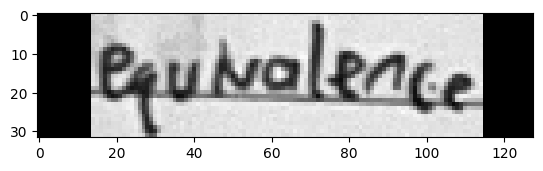

1/1 [==============================] - 0s 118ms/step
=============== New Img ===============
tf.Tensor([12 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1], shape=(21,), dtype=int64)
['.']


In [79]:
srno = 43
box = prediction_groups[0][srno]

res = WordBox(box)
DisplayWord(res)
res = tf.reshape(res, [1] + list(res.shape))
preds = prediction_model.predict(res)
pred_texts = decode_batch_predictions(preds)
print(pred_texts)

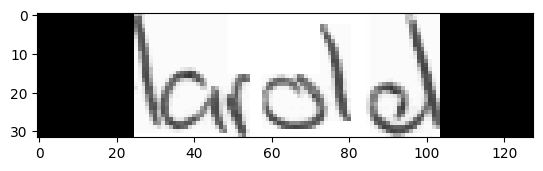

1/1 [==============================] - 6s 6s/step
=============== New Img ===============
[[[6.7890547e-11 2.5191682e-04 4.2322423e-02 ... 7.5222961e-06
   5.5630906e-11 9.0419455e-04]
  [7.9634235e-15 1.7973903e-07 2.0831909e-05 ... 6.2068151e-09
   8.7317077e-15 9.9872988e-01]
  [1.1430687e-16 3.2725125e-09 4.4198958e-07 ... 1.4574957e-10
   1.4951541e-16 9.9992800e-01]
  ...
  [1.6646490e-20 5.4379851e-12 1.4609893e-12 ... 1.1416798e-13
   1.3818073e-20 1.0000000e+00]
  [1.2154863e-17 2.5498451e-10 8.3523910e-11 ... 2.0385039e-11
   9.9230828e-18 9.9999678e-01]
  [1.4326821e-12 1.0178587e-06 1.5375086e-06 ... 6.1365978e-07
   1.1139962e-12 9.9408013e-01]]]
tf.Tensor([12 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1], shape=(21,), dtype=int64)
['.']


In [87]:
test_img = tf.io.read_file("C:\\Work\\Programming\\Hackathons\\Reprose\\Notes generation\\data\\words\\a06\\a06-008\\a06-008-00-01.png")
test_img = tf.image.decode_jpeg(test_img, 1)
test_img = tf.cast(test_img, tf.float32) / 255.0
test_img = preprocess_image(test_img)

DisplayWord(test_img)

test_img = tf.reshape(test_img, [1] + list(test_img.shape))

preds = prediction_model.predict(test_img)
pred_texts = decode_batch_predictions(preds)
print(pred_texts)

# This needs to be fixed; gives a different otuput to the output given by the model in the other ipynb file